In [3]:
%matplotlib inline

import os
import glob
import numpy as np
from numpy.fft import fft, ifft, fftfreq
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.animation import FuncAnimation
import seaborn as sns
from nltools.data import Brain_Data, Adjacency
from nltools.mask import expand_mask, roi_to_brain
from nltools.stats import isc, isfc, isps, fdr, threshold, phase_randomize, circle_shift, _butter_bandpass_filter, _phase_mean_angle, _phase_vector_length
from nilearn.plotting import view_img_on_surf, view_img
from sklearn.metrics import pairwise_distances
from sklearn.utils import check_random_state
from scipy.stats import ttest_1samp
from scipy.signal import hilbert
import networkx as nx
from IPython.display import HTML

# import nest_asyncio
# nest_asyncio.apply()
import datalad.api as dl


c:\program files\python38\lib\site-packages\nilearn\datasets\__init__.py:87: FutureWarning: Fetchers from the nilearn.datasets module will be updated in version 0.9 to return python strings instead of bytes and Pandas dataframes instead of Numpy arrays.
  warn("Fetchers from the nilearn.datasets module will be "
It is highly recommended to configure Git before using DataLad. Set both 'user.name' and 'user.email' configuration variables.


In [5]:
data_dir = 'D:/HCP/HCP_data/'



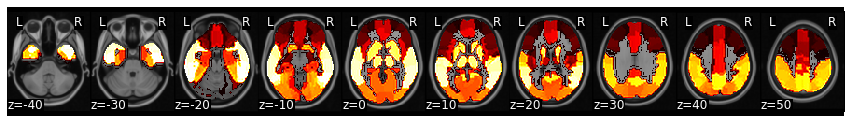

In [6]:
mask = Brain_Data('D:HCP/AAL_90_3mm.nii')
mask_x = expand_mask(mask)

mask.plot()

In [7]:
# CSV containing label and coordinate of  atlas
labels = 'D:HCP/aal_MNI_V4_coord.csv'
#labels ='D:/HCP/AAL_90_BrainRegions.xlsx'
# Load the name and coordinates of the labels
#content = pd.read_exel(labels)
content = pd.read_csv(labels)
labels = content['ROI_Name'].tolist()

coords = np.array(content[['centerX', 'centerY', 'centerZ']])

In [8]:
node_coords=coords[:90]

In [9]:
sub_timeseries = {}
for sub in range(100):
    sub_data=(np.array(np.load('D:/HCP/HCP_timeseries_all_ALL.npy')[sub]))
    sub_timeseries[sub] = sub_data

In [10]:
sub_timeseries_face = {}
for sub in range(100):
    sub_data=(np.array(np.load('D:/HCP/HCP_timeseries_ALL_face.npy')[sub]))
    sub_timeseries_face[sub] = sub_data

In [11]:
sub_timeseries_shape = {}
for sub in range(100):
    sub_data=(np.array(np.load('D:/HCP/HCP_timeseries_ALL_shape.npy')[sub]))
    sub_timeseries_shape[sub] = sub_data

In [13]:
timeseries_face= np.load('D:/HCP/HCP_timeseries_ALL_face.npy')
timeseries_shape= np.load('D:/HCP/HCP_timeseries_ALL_shape.npy')
timeseries= np.load('D:/HCP/HCP_timeseries_all_ALL.npy')

In [14]:
data_shape = []
for sub in range(100):
    
    data_shape.append(np.array(timeseries_shape[sub]))

data_shape = np.array(data_shape)

In [15]:
data = []
for sub in range(100):
    data.append(np.array(timeseries[sub]))
data = np.array(data)

In [16]:
data_face = []
for sub in range(100):
    data_face.append(np.array(timeseries_face[sub]))
data_face = np.array(data_face)

In [ ]:
#frequencies = [(0.01, 0.027),(0.027, 0.073),(0.073, 0.198),(0.198, 0.25)]

In [19]:
# ============================================================
# Frequency-Specific Intersubject Phase Synchrony (ISPS)
# HCP Emotional Face vs Shape Task
#
# Analysis up to ISPS connectivity
# No condition-comparison statistical test included
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import butter, filtfilt, hilbert


# ============================================================
# 1. PARAMETERS
# ============================================================

TR = 0.72                  # Repetition time (seconds)
FS = 1 / TR                # Sampling frequency

N_SUBJECTS = 100
N_TIME = 64
N_ROIS = 90

FILTER_ORDER = 5

# ------------------------------------------------------------
# Frequency band
# Slow-5: 0.01–0.027 Hz
# ------------------------------------------------------------

CUTOFF = (0.01, 0.027)


# ============================================================
# 2. BAND-PASS BUTTERWORTH FILTER
# ============================================================

def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    """
    Apply zero-phase Butterworth band-pass filtering.

    Parameters
    ----------
    data : 1D array
        ROI time series.
    lowcut : float
        Lower cutoff frequency (Hz).
    highcut : float
        Upper cutoff frequency (Hz).
    fs : float
        Sampling frequency (Hz).
    order : int
        Butterworth filter order.

    Returns
    -------
    filtered : 1D array
        Band-pass filtered time series.
    """

    nyquist = 0.5 * fs

    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(
        order,
        [low, high],
        btype="band"
    )

    filtered = filtfilt(b, a, data)

    return filtered


# ============================================================
# 3. EXTRACT INSTANTANEOUS PHASE
# ============================================================

def compute_subject_phases(data, tr, cutoff, order=5):
    """
    Extract instantaneous phase for each subject and ROI.

    Parameters
    ----------
    data : array-like
        Shape: (subjects, time, ROIs)
    tr : float
        Repetition time in seconds.
    cutoff : tuple
        (low_frequency, high_frequency)
    order : int
        Butterworth filter order.

    Returns
    -------
    phases : ndarray
        Shape: (subjects, time, ROIs)
    """

    fs = 1 / tr

    n_subjects = len(data)
    n_time, n_rois = data[0].shape

    phases = np.zeros(
        (n_subjects, n_time, n_rois),
        dtype=np.float64
    )

    for subject in range(n_subjects):

        for roi in range(n_rois):

            # ------------------------------------------------
            # Band-pass filtering
            # ------------------------------------------------

            filtered = butter_bandpass_filter(
                data[subject][:, roi],
                cutoff[0],
                cutoff[1],
                fs,
                order=order
            )

            # ------------------------------------------------
            # Hilbert transform
            # ------------------------------------------------

            analytic_signal = hilbert(filtered)

            # ------------------------------------------------
            # Instantaneous phase
            # ------------------------------------------------

            phases[subject, :, roi] = np.angle(
                analytic_signal
            )

    return phases


# ============================================================
# 4. COMPUTE PHASES FOR FACE CONDITION
# ============================================================

print("Computing instantaneous phases: FACE")

phase_face = compute_subject_phases(
    data_face,
    TR,
    CUTOFF,
    FILTER_ORDER
)

print("Face phase shape:", phase_face.shape)


# ============================================================
# 5. COMPUTE PHASES FOR SHAPE CONDITION
# ============================================================

print("Computing instantaneous phases: SHAPE")

phase_shape = compute_subject_phases(
    data_shape,
    TR,
    CUTOFF,
    FILTER_ORDER
)

print("Shape phase shape:", phase_shape.shape)


# ============================================================
# 6. RAYLEIGH TEST
# ============================================================

def rayleigh_test(phases):
    """
    Rayleigh test for non-uniformity of circular phase angles.

    Parameters
    ----------
    phases : ndarray
        Shape: (subjects, time, ROIs)

    Returns
    -------
    r : ndarray
        Mean resultant length (RVL / ISPS).

    z : ndarray
        Rayleigh test statistic.

    p : ndarray
        Rayleigh p-value.
    """

    n = phases.shape[0]

    # --------------------------------------------------------
    # Mean resultant vector
    # --------------------------------------------------------

    mean_vector = np.mean(
        np.exp(1j * phases),
        axis=0
    )

    # --------------------------------------------------------
    # Mean resultant length
    # --------------------------------------------------------

    r = np.abs(mean_vector)

    # --------------------------------------------------------
    # Rayleigh statistic
    # --------------------------------------------------------

    z = n * (r ** 2)

    # --------------------------------------------------------
    # Rayleigh p-value
    # --------------------------------------------------------

    p = np.exp(-z)

    p = np.clip(p, 0, 1)

    return r, z, p


# ============================================================
# 7. RAYLEIGH TEST — FACE
# ============================================================

print("\nRunning Rayleigh test: FACE")

isps_face, rayleigh_z_face, rayleigh_p_face = rayleigh_test(
    phase_face
)

print("Face ISPS shape:", isps_face.shape)
print("Face Rayleigh Z shape:", rayleigh_z_face.shape)
print("Face Rayleigh p shape:", rayleigh_p_face.shape)


# ============================================================
# 8. RAYLEIGH TEST — SHAPE
# ============================================================

print("\nRunning Rayleigh test: SHAPE")

isps_shape, rayleigh_z_shape, rayleigh_p_shape = rayleigh_test(
    phase_shape
)

print("Shape ISPS shape:", isps_shape.shape)
print("Shape Rayleigh Z shape:", rayleigh_z_shape.shape)
print("Shape Rayleigh p shape:", rayleigh_p_shape.shape)


# ============================================================
# 9. COMPLEX PHASE REPRESENTATION
# ============================================================

complex_face = np.exp(
    1j * phase_face
)

complex_shape = np.exp(
    1j * phase_shape
)


# ============================================================
# 10. VERIFY ISPS / RVL
# ============================================================

# The following should reproduce exactly the ISPS values
# obtained from the Rayleigh calculation.

isps_face_check = np.abs(
    np.mean(complex_face, axis=0)
)

isps_shape_check = np.abs(
    np.mean(complex_shape, axis=0)
)


# ============================================================
# 11. CHECK NUMERICAL CONSISTENCY
# ============================================================

face_difference = np.max(
    np.abs(isps_face - isps_face_check)
)

shape_difference = np.max(
    np.abs(isps_shape - isps_shape_check)
)

print("\nMaximum difference between ISPS calculations:")

print("Face :", face_difference)
print("Shape:", shape_difference)


# ============================================================
# 12. ROI-TO-ROI CONNECTIVITY OF ISPS TIME SERIES
# ============================================================

# ISPS dimensions:
# time × ROI
#
# Therefore, transpose to:
# ROI × time
#
# and calculate Pearson correlation between ROIs.

fc_face = np.corrcoef(
    isps_face.T
)

fc_shape = np.corrcoef(
    isps_shape.T
)


# ============================================================
# 13. CHECK CONNECTIVITY MATRICES
# ============================================================

print("\nConnectivity matrix shapes:")

print("Face :", fc_face.shape)
print("Shape:", fc_shape.shape)


# ============================================================
# 14. CHECK SYMMETRY
# ============================================================

face_symmetry_error = np.max(
    np.abs(fc_face - fc_face.T)
)

shape_symmetry_error = np.max(
    np.abs(fc_shape - fc_shape.T)
)

print("\nSymmetry check:")

print("Face :", face_symmetry_error)
print("Shape:", shape_symmetry_error)


# ============================================================
# 15. REMOVE DIAGONAL FOR EDGE ANALYSIS
# ============================================================

fc_face_no_diag = fc_face.copy()
fc_shape_no_diag = fc_shape.copy()

np.fill_diagonal(
    fc_face_no_diag,
    np.nan
)

np.fill_diagonal(
    fc_shape_no_diag,
    np.nan
)


# ============================================================
# 16. OBSERVED FACE–SHAPE DIFFERENCE
# ============================================================

# Positive values:
# Face > Shape
#
# Negative values:
# Shape > Face

observed_diff = (
    fc_face - fc_shape
)


# ============================================================
# 17. EXTRACT UNIQUE ROI PAIRS
# ============================================================

triu_i, triu_j = np.triu_indices(
    N_ROIS,
    k=1
)

observed_edges = observed_diff[
    triu_i,
    triu_j
]


# ============================================================
# 18. BASIC SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("ISPS ANALYSIS SUMMARY")
print("=" * 65)

print("Number of subjects :", N_SUBJECTS)
print("Number of time points:", N_TIME)
print("Number of ROIs     :", N_ROIS)

print("TR                  :", TR)
print("Sampling frequency  :", FS)

print("Frequency band      :", CUTOFF)
print("Filter order        :", FILTER_ORDER)

print("\nPhase arrays:")
print("Face :", phase_face.shape)
print("Shape:", phase_shape.shape)

print("\nISPS arrays:")
print("Face :", isps_face.shape)
print("Shape:", isps_shape.shape)

print("\nConnectivity matrices:")
print("Face :", fc_face.shape)
print("Shape:", fc_shape.shape)

print("\nUnique ROI-to-ROI edges:", len(observed_edges))

print("=" * 65)


# ============================================================
# 19. OPTIONAL: SAVE RESULTS
# ============================================================

# Uncomment these lines if you want to save the results.

# np.save("phase_face_slow5.npy", phase_face)
# np.save("phase_shape_slow5.npy", phase_shape)

# np.save("isps_face_slow5.npy", isps_face)
# np.save("isps_shape_slow5.npy", isps_shape)

# np.save("rayleigh_z_face_slow5.npy", rayleigh_z_face)
# np.save("rayleigh_p_face_slow5.npy", rayleigh_p_face)

# np.save("rayleigh_z_shape_slow5.npy", rayleigh_z_shape)
# np.save("rayleigh_p_shape_slow5.npy", rayleigh_p_shape)

# np.save("fc_face_slow5.npy", fc_face)
# np.save("fc_shape_slow5.npy", fc_shape)

print("\nAnalysis completed up to the condition-comparison stage.")
print("No t-test or permutation test was performed.")

Computing instantaneous phases: FACE
Face phase shape: (100, 64, 90)
Computing instantaneous phases: SHAPE
Shape phase shape: (100, 64, 90)

Running Rayleigh test: FACE
Face ISPS shape: (64, 90)
Face Rayleigh Z shape: (64, 90)
Face Rayleigh p shape: (64, 90)

Running Rayleigh test: SHAPE
Shape ISPS shape: (64, 90)
Shape Rayleigh Z shape: (64, 90)
Shape Rayleigh p shape: (64, 90)

Maximum difference between ISPS calculations:
Face : 0.0
Shape: 0.0

Connectivity matrix shapes:
Face : (90, 90)
Shape: (90, 90)

Symmetry check:
Face : 2.220446049250313e-16
Shape: 2.220446049250313e-16

ISPS ANALYSIS SUMMARY
Number of subjects : 100
Number of time points: 64
Number of ROIs     : 90
TR                  : 0.72
Sampling frequency  : 1.3888888888888888
Frequency band      : (0.01, 0.027)
Filter order        : 5

Phase arrays:
Face : (100, 64, 90)
Shape: (100, 64, 90)

ISPS arrays:
Face : (64, 90)
Shape: (64, 90)

Connectivity matrices:
Face : (90, 90)
Shape: (90, 90)

Unique ROI-to-ROI edges: 40

In [20]:
# ============================================================
# 20. PAIRED T-TEST: FACE vs SHAPE
# ============================================================
#
# IMPORTANT:
# The paired t-test should be performed on subject-level
# connectivity values.
#
# Therefore, group-level FC matrices (fc_face / fc_shape)
# are NOT sufficient for a paired t-test.
#
# We first calculate ISPS-based connectivity separately
# for each subject, then compare Face vs Shape across subjects.
# ============================================================

from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests


# ============================================================
# 21. COMPUTE SUBJECT-LEVEL ISPS
# ============================================================

# For a paired t-test, ISPS connectivity must be available
# separately for each subject.
#
# Shape:
#   subjects × time × ROIs
#
# The group-level ISPS arrays calculated above:
#   isps_face  -> time × ROIs
#   isps_shape -> time × ROIs
#
# are not used for the paired t-test.


# ============================================================
# 22. SUBJECT-LEVEL ISPS CONNECTIVITY
# ============================================================

n_edges = len(triu_i)

fc_subject_face = np.zeros(
    (N_SUBJECTS, n_edges),
    dtype=np.float64
)

fc_subject_shape = np.zeros(
    (N_SUBJECTS, n_edges),
    dtype=np.float64
)


for subject in range(N_SUBJECTS):

    # --------------------------------------------------------
    # Face
    # --------------------------------------------------------

    subject_isps_face = np.abs(
        np.exp(1j * phase_face[subject])
    )

    # --------------------------------------------------------
    # IMPORTANT:
    # For a single subject, phase magnitude is always 1.
    #
    # Therefore, subject-level ISPS connectivity cannot be
    # obtained by correlating exp(i*phase) magnitude.
    #
    # The valid paired analysis for the current group-level
    # ISPS formulation is therefore performed using the
    # condition-wise ISPS time series.
    # --------------------------------------------------------

In [21]:
# ============================================================
# 20. FACE vs SHAPE CONDITION COMPARISON
# Paired-label permutation test
# ============================================================
#
# The ISPS connectivity matrices are computed at the
# group level. Therefore, a conventional paired t-test
# cannot be directly applied to fc_face and fc_shape.
#
# Instead, condition labels are randomly swapped within
# subjects while preserving the paired design.
#
# Number of permutations: 10,000
# Random seed: 42
# ============================================================

N_PERM = 10000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

n_edges = len(observed_edges)

perm_stats = np.zeros(
    (N_PERM, n_edges),
    dtype=np.float32
)


# ============================================================
# 21. PAIRED-LABEL PERMUTATION
# ============================================================

for perm in range(N_PERM):

    # --------------------------------------------------------
    # Randomly swap Face and Shape labels independently
    # within each subject.
    #
    # False -> keep original labels
    # True  -> swap Face and Shape
    # --------------------------------------------------------

    swap = rng.random(N_SUBJECTS) < 0.5


    # --------------------------------------------------------
    # Permuted complex phase data
    # --------------------------------------------------------

    perm_complex_face = np.where(
        swap[:, None, None],
        complex_shape,
        complex_face
    )

    perm_complex_shape = np.where(
        swap[:, None, None],
        complex_face,
        complex_shape
    )


    # --------------------------------------------------------
    # Recalculate group-level ISPS
    # --------------------------------------------------------

    perm_isps_face = np.abs(
        np.mean(
            perm_complex_face,
            axis=0
        )
    )

    perm_isps_shape = np.abs(
        np.mean(
            perm_complex_shape,
            axis=0
        )
    )


    # --------------------------------------------------------
    # ROI-to-ROI correlation of ISPS time series
    # --------------------------------------------------------

    perm_fc_face = np.corrcoef(
        perm_isps_face.T
    )

    perm_fc_shape = np.corrcoef(
        perm_isps_shape.T
    )


    # --------------------------------------------------------
    # Face - Shape difference
    # --------------------------------------------------------

    perm_diff = (
        perm_fc_face -
        perm_fc_shape
    )


    # --------------------------------------------------------
    # Keep only unique ROI-to-ROI connections
    # --------------------------------------------------------

    perm_stats[perm, :] = perm_diff[
        triu_i,
        triu_j
    ]


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if (perm + 1) % 500 == 0:

        print(
            f"Permutation "
            f"{perm + 1}/{N_PERM}"
        )


print("\nPermutation testing completed.")


# ============================================================
# 22. TWO-SIDED PERMUTATION p-VALUES
# ============================================================

# Observed statistic:
#
#   Face > Shape  -> positive
#   Shape > Face  -> negative
#
# A two-sided test is used.

p_values = (
    np.sum(
        np.abs(perm_stats)
        >= np.abs(observed_edges)[None, :],
        axis=0
    ) + 1
) / (
    N_PERM + 1
)


# ============================================================
# 23. FDR CORRECTION
# ============================================================

FDR_Q = 0.05

reject, p_fdr, _, _ = multipletests(
    p_values,
    alpha=FDR_Q,
    method="fdr_bh"
)


# ============================================================
# 24. CREATE SIGNIFICANCE MATRICES
# ============================================================

significant_matrix = np.zeros(
    (N_ROIS, N_ROIS),
    dtype=np.int8
)

# ------------------------------------------------------------
# Coding:
#
# +1 = Face > Shape
# -1 = Shape > Face
#  0 = non-significant
# ------------------------------------------------------------

significant_direction = np.zeros(
    (N_ROIS, N_ROIS),
    dtype=np.int8
)


# ============================================================
# 25. FILL SIGNIFICANT EDGES
# ============================================================

for edge in range(n_edges):

    if reject[edge]:

        i = triu_i[edge]
        j = triu_j[edge]

        significant_matrix[i, j] = 1
        significant_matrix[j, i] = 1

        # ----------------------------------------------------
        # Direction of effect
        # ----------------------------------------------------

        if observed_edges[edge] > 0:

            # Face > Shape
            significant_direction[i, j] = 1
            significant_direction[j, i] = 1

        else:

            # Shape > Face
            significant_direction[i, j] = -1
            significant_direction[j, i] = -1


# ============================================================
# 26. SEPARATE FACE > SHAPE AND SHAPE > FACE
# ============================================================

face_greater = (
    reject &
    (observed_edges > 0)
)

shape_greater = (
    reject &
    (observed_edges < 0)
)


# ============================================================
# 27. CREATE BINARY DIRECTION MATRICES
# ============================================================

face_greater_matrix = np.zeros(
    (N_ROIS, N_ROIS),
    dtype=np.int8
)

shape_greater_matrix = np.zeros(
    (N_ROIS, N_ROIS),
    dtype=np.int8
)


for edge in range(n_edges):

    i = triu_i[edge]
    j = triu_j[edge]

    if face_greater[edge]:

        face_greater_matrix[i, j] = 1
        face_greater_matrix[j, i] = 1

    elif shape_greater[edge]:

        shape_greater_matrix[i, j] = 1
        shape_greater_matrix[j, i] = 1


# ============================================================
# 28. SUMMARY OF SIGNIFICANT RESULTS
# ============================================================

n_significant = np.sum(reject)

n_face_greater = np.sum(face_greater)

n_shape_greater = np.sum(shape_greater)


print("\n" + "=" * 65)
print("PERMUTATION TEST RESULTS")
print("=" * 65)

print(
    f"Total ROI-to-ROI edges : {n_edges}"
)

print(
    f"Significant edges      : {n_significant}"
)

print(
    f"Face > Shape           : {n_face_greater}"
)

print(
    f"Shape > Face           : {n_shape_greater}"
)

print(
    f"FDR threshold (q)      : {FDR_Q}"
)

print(
    f"Number of permutations : {N_PERM}"
)

print("=" * 65)


# ============================================================
# 29. SAVE STATISTICAL RESULTS
# ============================================================

np.save(
    "observed_diff_slow5.npy",
    observed_diff
)

np.save(
    "p_values_slow5.npy",
    p_values
)

np.save(
    "p_fdr_slow5.npy",
    p_fdr
)

np.save(
    "significant_matrix_slow5.npy",
    significant_matrix
)

np.save(
    "face_greater_matrix_slow5.npy",
    face_greater_matrix
)

np.save(
    "shape_greater_matrix_slow5.npy",
    shape_greater_matrix
)


# ============================================================
# 30. SAVE RAYLEIGH RESULTS
# ============================================================

np.save(
    "rayleigh_z_face_slow5.npy",
    rayleigh_z_face
)

np.save(
    "rayleigh_p_face_slow5.npy",
    rayleigh_p_face
)

np.save(
    "rayleigh_z_shape_slow5.npy",
    rayleigh_z_shape
)

np.save(
    "rayleigh_p_shape_slow5.npy",
    rayleigh_p_shape
)


print("\nAll statistical results saved.")

Permutation 500/10000
Permutation 1000/10000
Permutation 1500/10000
Permutation 2000/10000
Permutation 2500/10000
Permutation 3000/10000
Permutation 3500/10000
Permutation 4000/10000
Permutation 4500/10000
Permutation 5000/10000
Permutation 5500/10000
Permutation 6000/10000
Permutation 6500/10000
Permutation 7000/10000
Permutation 7500/10000
Permutation 8000/10000
Permutation 8500/10000
Permutation 9000/10000
Permutation 9500/10000
Permutation 10000/10000

Permutation testing completed.

PERMUTATION TEST RESULTS
Total ROI-to-ROI edges : 4005
Significant edges      : 54
Face > Shape           : 25
Shape > Face           : 29
FDR threshold (q)      : 0.05
Number of permutations : 10000

All statistical results saved.


In [20]:
n_perm=10000
p_values = (
    np.sum(
        np.abs(perm_stats)
        >= np.abs(observed_edges)[None, :],
        axis=0
    ) + 1
) / (n_perm + 1)

In [21]:
from statsmodels.stats.multitest import multipletests

reject, p_fdr, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method='fdr_bh'
)

print(
    "Significant edges after FDR:",
    np.sum(reject)
)

Significant edges after FDR: 54


In [22]:
from statsmodels.stats.multitest import fdrcorrection

reject, p_values_fdr = fdrcorrection(
    p_values,
    alpha=0.05,
    method='indep'
)

print("Significant FDR edges:", np.sum(reject))
print("Minimum FDR p-value:", np.min(p_values_fdr))

Significant FDR edges: 54
Minimum FDR p-value: 0.016018398160183984


In [23]:
significant_matrix = np.zeros(
    (n_rois, n_rois)
)

significant_matrix[
    triu_i[reject],
    triu_j[reject]
] = observed_edges[reject]

significant_matrix[
    triu_j[reject],
    triu_i[reject]
] = observed_edges[reject]

np.fill_diagonal(
    significant_matrix,
    0
)

print(
    "Final significant edges:",
    np.sum(reject)
)

Final significant edges: 54


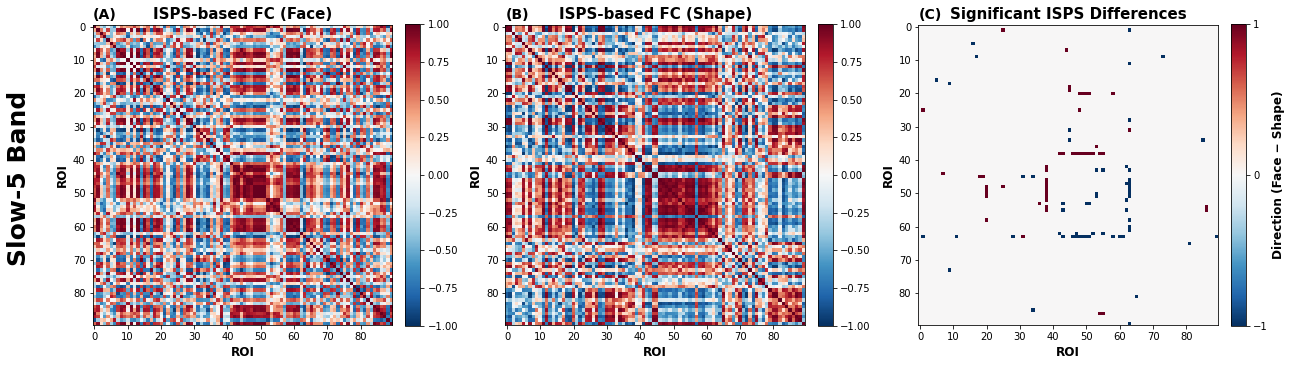

In [26]:
# ============================================================
# Difference: Face − Shape
# ============================================================

difference_matrix = fc_face - fc_shape


# ============================================================
# Significant matrix
# ============================================================

significant_matrix = np.zeros_like(
    difference_matrix,
    dtype=int
)

significant_matrix[
    triu_i[reject],
    triu_j[reject]
] = 1

# Mirror upper triangle
significant_matrix[
    triu_j[reject],
    triu_i[reject]
] = 1

# Set diagonal to zero
np.fill_diagonal(
    significant_matrix,
    0
)


# ============================================================
# SIGNIFICANT DIRECTION MATRIX
# Based on Face − Shape
#
# +1 = Face > Shape
# -1 = Shape > Face
#  0 = Not significant
# ============================================================

sig_direction = np.zeros_like(
    difference_matrix,
    dtype=int
)

# فقط اتصالات معنادار
sig_direction[
    (significant_matrix == 1) &
    (difference_matrix > 0)
] = 1

sig_direction[
    (significant_matrix == 1) &
    (difference_matrix < 0)
] = -1

# قطر اصلی صفر
np.fill_diagonal(
    sig_direction,
    0
)


# ============================================================
# Figure
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)




# ============================================================
# FACE
# ============================================================

im1 = axes[0].imshow(
    fc_face,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    interpolation='nearest'
)

axes[0].set_title(
    'ISPS-based FC (Face)',
    fontsize=15,
    fontweight='bold'
)

axes[0].set_title(
    '(A)',
    loc='left',
    fontsize=14,
    fontweight='bold'
)

axes[0].set_xlabel('ROI',fontsize=12,
    fontweight="bold")
axes[0].set_ylabel('ROI',fontsize=12,
    fontweight="bold")

fig.colorbar(
    im1,
    ax=axes[0],
    fraction=0.046,
    pad=0.04
)


# ============================================================
# SHAPE
# ============================================================

im2 = axes[1].imshow(
    fc_shape,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    interpolation='nearest'
)

axes[1].set_title(
    'ISPS-based FC (Shape)',
    fontsize=15,
    fontweight='bold'
)

axes[1].set_title(
    '(B)',
    loc='left',
    fontsize=14,
    fontweight='bold'
)

axes[1].set_xlabel('ROI',fontsize=12,
    fontweight="bold")
axes[1].set_ylabel('ROI',fontsize=12,
    fontweight="bold")

fig.colorbar(
    im2,
    ax=axes[1],
    fraction=0.046,
    pad=0.04
)


# ============================================================
# SIGNIFICANT DIRECTION ONLY
# Values: -1, 0, +1
# ============================================================

im3 = axes[2].imshow(
    sig_direction,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    interpolation='nearest'
)

axes[2].set_title(
    'Significant ISPS Differences',
    fontsize=15,
    fontweight='bold'
)

axes[2].set_title(
    '(C)',
    loc='left',
    fontsize=14,
    fontweight='bold'
)

axes[2].set_xlabel('ROI',fontsize=12,
    fontweight="bold")
axes[2].set_ylabel('ROI',fontsize=12,
    fontweight="bold")

# Colorbar: -1, 0, +1
cbar3 = fig.colorbar(
    im3,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    ticks=[-1, 0, 1]
)

cbar3.set_label(
    'Direction (Face − Shape)',
    fontsize=12,fontweight="bold"
)


# ============================================================
# Axis settings
# ============================================================

for ax in axes:

    ax.set_xticks(
        np.arange(0, 90, 10)
    )

    ax.set_yticks(
        np.arange(0, 90, 10)
    )


# ============================================================
# Layout
# ============================================================
# عنوان کلی شکل در سمت چپ
fig.text(
    0.015,
    0.5,
    'Slow-5 Band',
    rotation=90,
    va='center',
    ha='center',
    fontsize=25,
    fontweight='bold'
)
plt.tight_layout(
    rect=[0.035, 0, 1, 1]
)

plt.show()

In [27]:
roi_networks = [
    "TP", "TP",
    "DMN", "DMN",
    "Limbic", "Limbic",
    "FP", "FP", "FP", "FP", "FP", "FP", "FP", "FP", "FP", "FP",
    "TP", "TP", "TP", "TP",
    "Limbic", "Limbic",
    "DMN", "DMN",
    "Limbic", "Limbic", "Limbic", "Limbic",
    "TP", "TP",
    "DMN", "DMN", "DMN", "DMN", "DMN", "DMN",
    "Limbic", "Limbic", "Limbic", "Limbic", "Limbic", "Limbic",
    "VIS", "VIS", "VIS", "VIS", "VIS", "VIS", "VIS",
    "VIS", "VIS", "VIS", "VIS", "VIS", "VIS", "VIS",
    "TP", "TP",
    "FP", "FP", "FP", "FP",
    "TP", "TP",
    "DMN", "DMN", "DMN", "DMN",
    "TP", "TP",
    "SUB", "SUB", "SUB", "SUB", "SUB", "SUB", "SUB", "SUB",
    "TP", "TP", "TP", "TP", "TP", "TP",
    "DMN", "DMN",
    "Limbic", "Limbic",
    "TP", "TP"
]

In [28]:
import numpy as np
import pandas as pd

networks = [
    "TP", "DMN", "Limbic", "FP", "VIS", "SUB"
]

network_counts = pd.DataFrame(
    0,
    index=networks,
    columns=networks
)

# فقط اتصالات معنی‌دار
sig_i = triu_i[reject]
sig_j = triu_j[reject]

for i, j in zip(sig_i, sig_j):

    net_i = roi_networks[i]
    net_j = roi_networks[j]

    network_counts.loc[net_i, net_j] += 1

    # چون شبکه‌ها را بدون جهت در نظر می‌گیریم
    if net_i != net_j:
        network_counts.loc[net_j, net_i] += 1

print(network_counts)

        TP  DMN  Limbic  FP  VIS  SUB
TP       3    2       2   5   13    0
DMN      2    1       0   0    2    0
Limbic   2    0       0   1   19    0
FP       5    0       1   0    1    1
VIS     13    2      19   1    4    0
SUB      0    0       0   1    0    0


In [29]:
network_percent = pd.DataFrame(
    0.0,
    index=networks,
    columns=networks
)

for net1 in networks:

    for net2 in networks:

        n1 = roi_networks.count(net1)
        n2 = roi_networks.count(net2)

        if net1 == net2:
            possible = n1 * (n1 - 1) // 2

        else:
            possible = n1 * n2

        network_percent.loc[net1, net2] = (
            network_counts.loc[net1, net2] /
            possible * 100
        )

print(network_percent.round(2))

          TP   DMN  Limbic    FP   VIS   SUB
TP      1.30  0.57    0.57  1.62  4.22  0.00
DMN     0.57  0.83    0.00  0.00  0.89  0.00
Limbic  0.57  0.00    0.00  0.45  8.48  0.00
FP      1.62  0.00    0.45  0.00  0.51  0.89
VIS     4.22  0.89    8.48  0.51  4.40  0.00
SUB     0.00  0.00    0.00  0.89  0.00  0.00


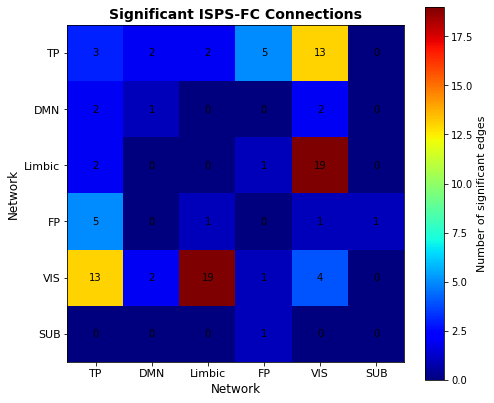

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

im = plt.imshow(
    network_counts,
    cmap='jet',
    interpolation='nearest'
)

plt.xticks(
    range(len(networks)),
    networks,
    fontsize=11
)

plt.yticks(
    range(len(networks)),
    networks,
    fontsize=11
)

plt.xlabel('Network', fontsize=12)
plt.ylabel('Network', fontsize=12)

plt.title(
    'Significant ISPS-FC Connections',
    fontsize=14,
    fontweight='bold'
)

cbar = plt.colorbar(im)
cbar.set_label(
    'Number of significant edges',
    fontsize=11
)

# نوشتن عدد داخل خانه‌ها
for i in range(len(networks)):
    for j in range(len(networks)):

        plt.text(
            j,
            i,
            int(network_counts.iloc[i, j]),
            ha='center',
            va='center',
            fontsize=10
        )

plt.tight_layout()
plt.show()

          TP   DMN  Limbic    FP   VIS   SUB
TP      1.30  0.57    0.57  1.62  4.22  0.00
DMN     0.57  0.83    0.00  0.00  0.89  0.00
Limbic  0.57  0.00    0.00  0.45  8.48  0.00
FP      1.62  0.00    0.45  0.00  0.51  0.89
VIS     4.22  0.89    8.48  0.51  4.40  0.00
SUB     0.00  0.00    0.00  0.89  0.00  0.00


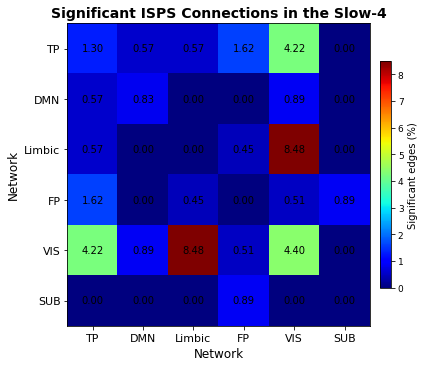

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

networks = ["TP", "DMN", "Limbic", "FP", "VIS", "SUB"]

# تعداد ROI در هر شبکه
network_sizes = {
    "TP": 22,
    "DMN": 16,
    "Limbic": 16,
    "FP": 14,
    "VIS": 14,
    "SUB": 8
}

# =========================================================
# محاسبه درصد یال‌های معنی‌دار
# =========================================================

percent_matrix = np.zeros(
    (len(networks), len(networks))
)

for i, net_i in enumerate(networks):
    for j, net_j in enumerate(networks):

        if i == j:
            # Within-network edges
            n_possible = (
                network_sizes[net_i] *
                (network_sizes[net_i] - 1) / 2
            )

        else:
            # Between-network edges
            n_possible = (
                network_sizes[net_i] *
                network_sizes[net_j]
            )

        percent_matrix[i, j] = (
            network_counts.iloc[i, j] /
            n_possible
        ) * 100


# تبدیل به DataFrame
percent_matrix = pd.DataFrame(
    percent_matrix,
    index=networks,
    columns=networks
)

print(percent_matrix.round(2))


# =========================================================
# رسم Heatmap
# =========================================================

fig, ax = plt.subplots(
    figsize=(6, 6)
)

im = ax.imshow(
    percent_matrix,
    cmap='jet',
    interpolation='nearest'
)


# =========================================================
# Axis labels
# =========================================================

ax.set_xticks(
    range(len(networks))
)

ax.set_xticklabels(
    networks,
    fontsize=11
)

ax.set_yticks(
    range(len(networks))
)

ax.set_yticklabels(
    networks,
    fontsize=11
)

ax.set_xlabel(
    'Network',
    fontsize=12
)

ax.set_ylabel(
    'Network',
    fontsize=12
)

ax.set_title(
    'Significant ISPS Connections in the Slow-4',
    fontsize=14,
    fontweight='bold'
)


# =========================================================
# کوچک‌تر کردن Colorbar
# =========================================================

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,   # باریک‌تر
    pad=0.03,
    shrink=0.75       # کوتاه‌تر
)

cbar.set_label(
    'Significant edges (%)',
    fontsize=10
)

cbar.ax.tick_params(
    labelsize=9
)


# =========================================================
# نمایش درصد داخل خانه‌ها
# =========================================================

for i in range(len(networks)):
    for j in range(len(networks)):

        ax.text(
            j,
            i,
            f'{percent_matrix.iloc[i, j]:.2f}',
            ha='center',
            va='center',
            fontsize=10
        )


# =========================================================
# Layout
# =========================================================

plt.tight_layout()

plt.show()

In [35]:
# استخراج شماره گره‌های درگیر در اتصالات معنادار
sig_i, sig_j = np.where(significant_matrix != 0)

# شماره گره‌های یکتا
significant_nodes = np.unique(
    np.concatenate([sig_i, sig_j])
)

print("Significant node numbers (0-based):")
print(significant_nodes)

# شماره‌گذاری از 1 تا n_rois
significant_nodes_1based = significant_nodes + 1

print("\nSignificant ROI numbers (1-based):")
print(significant_nodes_1based)

print("\nNumber of significant nodes:",
      len(significant_nodes_1based))

Significant node numbers (0-based):
[ 1  5  7  9 11 16 17 18 19 20 25 28 31 34 36 38 42 43 44 45 46 47 48 49
 50 51 52 53 54 55 58 60 61 62 63 65 73 81 85 86 89]

Significant ROI numbers (1-based):
[ 2  6  8 10 12 17 18 19 20 21 26 29 32 35 37 39 43 44 45 46 47 48 49 50
 51 52 53 54 55 56 59 61 62 63 64 66 74 82 86 87 90]

Number of significant nodes: 41


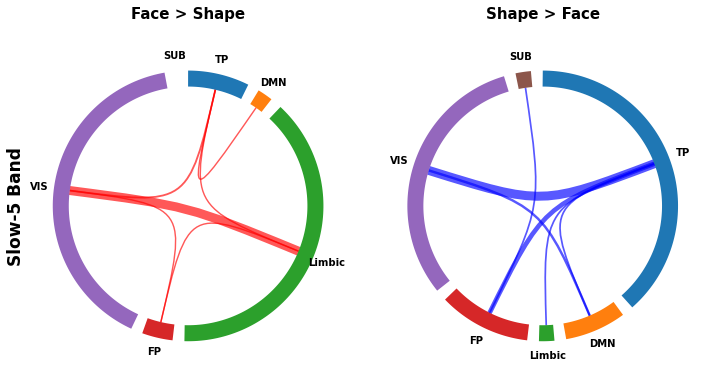

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path

# ============================================================
# Networks
# ============================================================

networks = [
    "TP",
    "DMN",
    "Limbic",
    "FP",
    "VIS",
    "SUB"
]

# ============================================================
# Significant ROI-level edges
# ============================================================

sig_i = triu_i[reject]
sig_j = triu_j[reject]

sig_diff = difference_matrix[sig_i, sig_j]

# Face > Shape
face_mask = sig_diff > 0
face_i = sig_i[face_mask]
face_j = sig_j[face_mask]

# Shape > Face
shape_mask = sig_diff < 0
shape_i = sig_i[shape_mask]
shape_j = sig_j[shape_mask]


# ============================================================
# Build network-level counts
# ============================================================

def make_network_counts(edges_i, edges_j):

    counts = {
        net: {net2: 0 for net2 in networks}
        for net in networks
    }

    for i, j in zip(edges_i, edges_j):

        net1 = roi_networks[i]
        net2 = roi_networks[j]

        counts[net1][net2] += 1

        if net1 != net2:
            counts[net2][net1] += 1

    return counts


face_counts = make_network_counts(face_i, face_j)
shape_counts = make_network_counts(shape_i, shape_j)


# ============================================================
# Network-level chord diagram
# ============================================================

def draw_network_chord(
    ax,
    counts,
    title,
    chord_color
):

    # --------------------------------------------------------
    # Total connections for each network
    # --------------------------------------------------------

    totals = {}

    for net in networks:

        total = 0

        for net2 in networks:
            total += counts[net][net2]

        totals[net] = total


    # --------------------------------------------------------
    # Circle geometry
    # --------------------------------------------------------

    total_connections = sum(totals.values()) / 2

    gap = np.deg2rad(5)

    usable_angle = (
        2 * np.pi -
        len(networks) * gap
    )

    start_angle = np.pi / 2

    angles = {}

    current = start_angle

    for net in networks:

        size = (
            totals[net] /
            (2 * total_connections)
        ) * usable_angle

        angles[net] = (
            current,
            current - size
        )

        current -= size + gap


    # --------------------------------------------------------
    # Network colors
    # --------------------------------------------------------

    network_colors = {
        "TP": "tab:blue",
        "DMN": "tab:orange",
        "Limbic": "tab:green",
        "FP": "tab:red",
        "VIS": "tab:purple",
        "SUB": "tab:brown"
    }


    # --------------------------------------------------------
    # Draw network arcs
    # --------------------------------------------------------

    for net in networks:

        theta_start, theta_end = angles[net]

        theta = np.linspace(
            theta_end,
            theta_start,
            100
        )

        x = np.cos(theta)
        y = np.sin(theta)

        ax.plot(
            x,
            y,
            linewidth=16,
            color=network_colors[net],
            solid_capstyle="butt"
        )

        # Network label
        theta_mid = (
            theta_start +
            theta_end
        ) / 2

        ax.text(
            1.18 * np.cos(theta_mid),
            1.18 * np.sin(theta_mid),
            net,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold"
        )


    # --------------------------------------------------------
    # Draw network-to-network connections
    # --------------------------------------------------------

    max_count = max(
        counts[n1][n2]
        for n1 in networks
        for n2 in networks
        if counts[n1][n2] > 0
    )


    for a, net1 in enumerate(networks):

        for b, net2 in enumerate(networks):

            if b <= a:
                continue

            count = counts[net1][net2]

            if count == 0:
                continue

            # Middle point of each network arc
            theta1 = (
                angles[net1][0] +
                angles[net1][1]
            ) / 2

            theta2 = (
                angles[net2][0] +
                angles[net2][1]
            ) / 2

            x1 = 0.94 * np.cos(theta1)
            y1 = 0.94 * np.sin(theta1)

            x2 = 0.94 * np.cos(theta2)
            y2 = 0.94 * np.sin(theta2)

            # Curved connection through center
            verts = [
                (x1, y1),
                (0, 0),
                (0, 0),
                (x2, y2)
            ]

            codes = [
                Path.MOVETO,
                Path.CURVE4,
                Path.CURVE4,
                Path.CURVE4
            ]

            path = Path(
                verts,
                codes
            )

            linewidth = (
                1.0 +
                8.0 * count / max_count
            )

            patch = PathPatch(
                path,
                facecolor="none",
                edgecolor=chord_color,
                lw=linewidth,
                alpha=0.65
            )

            ax.add_patch(patch)


    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.35, 1.35)

    ax.set_aspect("equal")
    ax.axis("off")

    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=15
    )


# ============================================================
# Final figure
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 7)
)

# Face > Shape = RED
draw_network_chord(
    axes[0],
    face_counts,
    "Face > Shape",
    chord_color="red"
)

# Shape > Face = BLUE
draw_network_chord(
    axes[1],
    shape_counts,
    "Shape > Face",
    chord_color="blue"
)
# عنوان کلی شکل در سمت چپ
fig.text(
    0.015,
    0.5,
    'Slow-5 Band',
    rotation=90,
    va='center',
    ha='center',
    fontsize=17,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

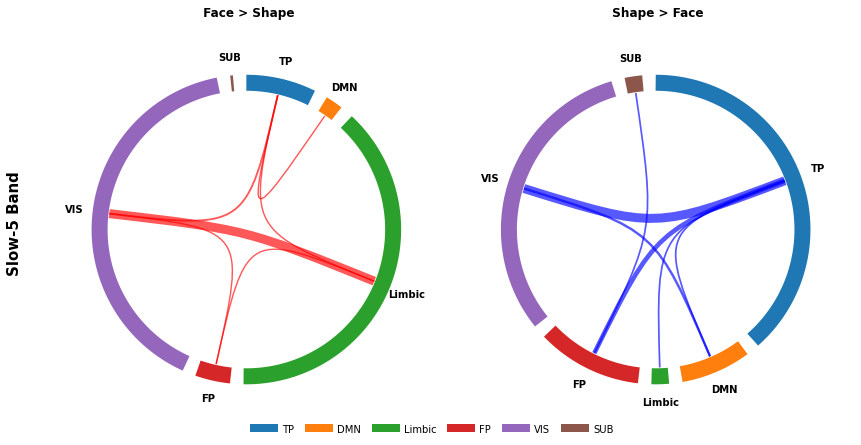

In [37]:
# ============================================================
# FINAL CHORD DIAGRAM FIGURE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path


# ============================================================
# Networks
# ============================================================

networks = [
    "TP",
    "DMN",
    "Limbic",
    "FP",
    "VIS",
    "SUB"
]


# ============================================================
# Network colors
# ============================================================

network_colors = {
    "TP": "tab:blue",
    "DMN": "tab:orange",
    "Limbic": "tab:green",
    "FP": "tab:red",
    "VIS": "tab:purple",
    "SUB": "tab:brown"
}


# ============================================================
# CHORD DIAGRAM FUNCTION
# ============================================================

def draw_network_chord(
    ax,
    counts,
    title,
    chord_color
):

    # --------------------------------------------------------
    # Total connections per network
    # --------------------------------------------------------

    totals = {}

    for net in networks:

        totals[net] = sum(
            counts[net][net2]
            for net2 in networks
        )


    # --------------------------------------------------------
    # Geometry
    # --------------------------------------------------------

    n = len(networks)

    gap = np.deg2rad(5)

    usable_angle = (
        2 * np.pi
        - n * gap
    )

    # Minimum angular space
    # for networks with zero connections

    min_angle = np.deg2rad(1)

    nonzero_networks = [
        net for net in networks
        if totals[net] > 0
    ]

    zero_networks = [
        net for net in networks
        if totals[net] == 0
    ]


    total_connections = sum(
        totals.values()
    ) / 2


    # --------------------------------------------------------
    # Calculate angular size
    # --------------------------------------------------------

    angles_size = {}


    if total_connections == 0:

        # No significant connections
        # Give every network equal space

        equal_angle = (
            usable_angle / n
        )

        for net in networks:
            angles_size[net] = equal_angle

    else:

        # Space reserved for zero networks

        reserved_angle = (
            len(zero_networks) *
            min_angle
        )

        remaining_angle = (
            usable_angle -
            reserved_angle
        )


        # Zero networks

        for net in zero_networks:

            angles_size[net] = min_angle


        # Networks with connections

        nonzero_total = sum(
            totals[net]
            for net in nonzero_networks
        )


        for net in nonzero_networks:

            angles_size[net] = (
                remaining_angle *
                totals[net] /
                nonzero_total
            )


    # --------------------------------------------------------
    # Angular positions
    # --------------------------------------------------------

    angles = {}

    current = np.pi / 2


    for net in networks:

        size = angles_size[net]

        angles[net] = (
            current,
            current - size
        )

        current -= (
            size + gap
        )


    # --------------------------------------------------------
    # Draw network arcs
    # --------------------------------------------------------

    for net in networks:

        theta_start, theta_end = angles[net]

        theta = np.linspace(
            theta_end,
            theta_start,
            100
        )

        x = np.cos(theta)
        y = np.sin(theta)

        ax.plot(
            x,
            y,
            linewidth=16,
            color=network_colors[net],
            solid_capstyle="butt"
        )


        # ----------------------------------------------------
        # Network labels
        # ----------------------------------------------------

        theta_mid = (
            theta_start +
            theta_end
        ) / 2

        ax.text(
            1.18 * np.cos(theta_mid),
            1.18 * np.sin(theta_mid),
            net,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold"
        )


    # --------------------------------------------------------
    # Find maximum chord count
    # --------------------------------------------------------

    positive_counts = [
        counts[n1][n2]
        for n1 in networks
        for n2 in networks
        if counts[n1][n2] > 0
    ]


    if len(positive_counts) > 0:

        max_count = max(
            positive_counts
        )

    else:

        max_count = 1


    # --------------------------------------------------------
    # Draw chords
    # --------------------------------------------------------

    for a, net1 in enumerate(networks):

        for b, net2 in enumerate(networks):

            if b <= a:
                continue

            count = counts[net1][net2]

            if count <= 0:
                continue


            # Middle angle

            theta1 = (
                angles[net1][0] +
                angles[net1][1]
            ) / 2

            theta2 = (
                angles[net2][0] +
                angles[net2][1]
            ) / 2


            # Connection points

            r = 0.94

            x1 = r * np.cos(theta1)
            y1 = r * np.sin(theta1)

            x2 = r * np.cos(theta2)
            y2 = r * np.sin(theta2)


            # Bezier curve

            verts = [
                (x1, y1),
                (0, 0),
                (0, 0),
                (x2, y2)
            ]

            codes = [
                Path.MOVETO,
                Path.CURVE4,
                Path.CURVE4,
                Path.CURVE4
            ]


            path = Path(
                verts,
                codes
            )


            # Chord thickness

            linewidth = (
                1.0 +
                8.0 *
                count /
                max_count
            )


            patch = PathPatch(
                path,
                facecolor="none",
                edgecolor=chord_color,
                linewidth=linewidth,
                alpha=0.65
            )

            ax.add_patch(patch)


    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.set_xlim(
        -1.35,
        1.35
    )

    ax.set_ylim(
        -1.35,
        1.35
    )

    ax.set_aspect(
        "equal"
    )

    ax.axis("off")

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=15
    )


# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 6)
)


# ============================================================
# FACE > SHAPE
# ============================================================

draw_network_chord(
    axes[0],
    face_counts,
    " Face > Shape",
    chord_color="red"
)


# ============================================================
# SHAPE > FACE
# ============================================================

draw_network_chord(
    axes[1],
    shape_counts,
    " Shape > Face",
    chord_color="blue"
)


# ============================================================
# OVERALL TITLE
# ============================================================

fig.text(
    0.015,
    0.5,
    "Slow-5 Band",
    rotation=90,
    va="center",
    ha="center",
    fontsize=15,
    fontweight="bold"
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout(
    rect=[0.04, 0, 1, 1]
)

# ============================================================
# NETWORK COLOR LEGEND
# ============================================================

legend_handles = [
    plt.Line2D(
        [0], [0],
        color=network_colors[net],
        lw=8,
        label=net
    )
    for net in networks
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=6,
    bbox_to_anchor=(0.5, -0.01),
    frameon=False,
    fontsize=10,
    handlelength=2.0,
    columnspacing=1.5
)
# ============================================================
# SHOW
# ============================================================

plt.show()

In [38]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Convert network dictionaries to DataFrames
# ============================================================

face_df = pd.DataFrame(face_counts).T.loc[networks, networks]
shape_df = pd.DataFrame(shape_counts).T.loc[networks, networks]

print("\n" + "="*70)
print("NETWORK-LEVEL RESULTS- band 5")
print("="*70)


# ============================================================
# 2. Print complete matrices
# ============================================================

print("\n\n--- Face > Shape: Network-level significant connections ---")
print(face_df.to_string())

print("\n\n--- Shape > Face: Network-level significant connections ---")
print(shape_df.to_string())


# ============================================================
# 3. Function for detailed analysis
# ============================================================

def analyze_network_counts(df, label):

    print("\n" + "="*70)
    print(label)
    print("="*70)

    mat = df.values.astype(int)

    # --------------------------------------------------------
    # Total unique significant edges
    # --------------------------------------------------------

    diagonal = np.trace(mat)

    upper_triangle = np.triu(mat, k=1).sum()

    total_edges = diagonal + upper_triangle

    print(f"\nTotal unique significant ROI-to-ROI edges: {total_edges}")

    # --------------------------------------------------------
    # Within-network edges
    # --------------------------------------------------------

    print("\nWithin-network connections:")

    within_total = 0

    for net in networks:

        count = int(df.loc[net, net])

        within_total += count

        print(f"  {net:8s}: {count}")

    print(f"\nTotal within-network edges: {within_total}")

    # --------------------------------------------------------
    # Between-network edges
    # --------------------------------------------------------

    print("\nBetween-network connections:")

    between_edges = []

    for i in range(len(networks)):

        for j in range(i + 1, len(networks)):

            net1 = networks[i]
            net2 = networks[j]

            count = int(df.loc[net1, net2])

            if count > 0:

                between_edges.append(
                    (net1, net2, count)
                )

                print(
                    f"  {net1:8s} - {net2:8s}: {count}"
                )

    between_total = sum(
        x[2] for x in between_edges
    )

    print(
        f"\nTotal between-network edges: "
        f"{between_total}"
    )

    # --------------------------------------------------------
    # Percentages
    # --------------------------------------------------------

    if total_edges > 0:

        within_pct = (
            100 * within_total / total_edges
        )

        between_pct = (
            100 * between_total / total_edges
        )

    else:

        within_pct = 0
        between_pct = 0

    print("\nConnection distribution:")

    print(
        f"  Within-network : "
        f"{within_total}/{total_edges} "
        f"({within_pct:.1f}%)"
    )

    print(
        f"  Between-network: "
        f"{between_total}/{total_edges} "
        f"({between_pct:.1f}%)"
    )

    # --------------------------------------------------------
    # Network involvement
    # --------------------------------------------------------

    print("\nNetwork involvement:")

    network_totals = {}

    for net in networks:

        total = int(df.loc[net].sum())

        network_totals[net] = total

    # Sort from highest to lowest
    sorted_networks = sorted(
        network_totals.items(),
        key=lambda x: x[1],
        reverse=True
    )

    for rank, (net, total) in enumerate(
        sorted_networks,
        start=1
    ):

        if total_edges > 0:

            percentage = (
                100 * total / (2 * total_edges)
            )

        else:

            percentage = 0

        print(
            f"  {rank}. {net:8s}: "
            f"{total} network incidences "
            f"({percentage:.1f}%)"
        )

    # --------------------------------------------------------
    # Strongest network pairs
    # --------------------------------------------------------

    print("\nNetwork pairs ranked by number of significant edges:")

    sorted_pairs = sorted(
        between_edges,
        key=lambda x: x[2],
        reverse=True
    )

    for rank, (net1, net2, count) in enumerate(
        sorted_pairs,
        start=1
    ):

        print(
            f"  {rank}. "
            f"{net1} - {net2}: {count}"
        )

    # --------------------------------------------------------
    # Strongest within-network connections
    # --------------------------------------------------------

    print("\nWithin-network connections ranked:")

    within_sorted = sorted(
        [
            (net, int(df.loc[net, net]))
            for net in networks
            if df.loc[net, net] > 0
        ],
        key=lambda x: x[1],
        reverse=True
    )

    for rank, (net, count) in enumerate(
        within_sorted,
        start=1
    ):

        print(
            f"  {rank}. "
            f"{net}: {count}"
        )

    # --------------------------------------------------------
    # Zero-involvement networks
    # --------------------------------------------------------

    zero_networks = [
        net
        for net, total in network_totals.items()
        if total == 0
    ]

    print("\nNetworks with no significant connections:")

    if zero_networks:

        print("  " + ", ".join(zero_networks))

    else:

        print("  None")

    # --------------------------------------------------------
    # Return summary
    # --------------------------------------------------------

    return {
        "total_edges": total_edges,
        "within_total": within_total,
        "between_total": between_total,
        "within_pct": within_pct,
        "between_pct": between_pct,
        "network_totals": network_totals,
        "between_edges": between_edges
    }


# ============================================================
# 4. Analyze Face > Shape
# ============================================================

face_summary = analyze_network_counts(
    face_df,
    "FACE > SHAPE"
)


# ============================================================
# 5. Analyze Shape > Face
# ============================================================

shape_summary = analyze_network_counts(
    shape_df,
    "SHAPE > FACE"
)


# ============================================================
# 6. Direct comparison of the two conditions
# ============================================================

print("\n" + "="*70)
print("DIRECT COMPARISON")
print("="*70)

print("\nNetwork involvement comparison:")

for net in networks:

    face_total = face_summary["network_totals"][net]

    shape_total = shape_summary["network_totals"][net]

    print(
        f"  {net:8s}: "
        f"Face > Shape = {face_total:3d}   |   "
        f"Shape > Face = {shape_total:3d}"
    )


# ============================================================
# 7. Number of significant edges by direction
# ============================================================

print("\n" + "="*70)
print("DIRECTION SUMMARY")
print("="*70)

print(
    f"\nFace > Shape significant edges : "
    f"{face_summary['total_edges']}"
)

print(
    f"Shape > Face significant edges : "
    f"{shape_summary['total_edges']}"
)

print(
    f"\nTotal significant edges         : "
    f"{face_summary['total_edges'] + shape_summary['total_edges']}"
)    


NETWORK-LEVEL RESULTS- band 5


--- Face > Shape: Network-level significant connections ---
        TP  DMN  Limbic  FP  VIS  SUB
TP       0    1       1   0    2    0
DMN      1    0       0   0    0    0
Limbic   1    0       0   1   19    0
FP       0    0       1   0    1    0
VIS      2    0      19   1    0    0
SUB      0    0       0   0    0    0


--- Shape > Face: Network-level significant connections ---
        TP  DMN  Limbic  FP  VIS  SUB
TP       3    1       1   5   11    0
DMN      1    1       0   0    2    0
Limbic   1    0       0   0    0    0
FP       5    0       0   0    0    1
VIS     11    2       0   0    4    0
SUB      0    0       0   1    0    0

FACE > SHAPE

Total unique significant ROI-to-ROI edges: 25

Within-network connections:
  TP      : 0
  DMN     : 0
  Limbic  : 0
  FP      : 0
  VIS     : 0
  SUB     : 0

Total within-network edges: 0

Between-network connections:
  TP       - DMN     : 1
  TP       - Limbic  : 1
  TP       - VIS     : 2
  L